# NB4 — Swin-Tiny Transformer: CORAL Ordinal Severity Classification
**Stages:** AKIEC(0) → BCC(1) → SCC(2) → MEL(3)

| Strategy | Implementation |
|----------|---------------|
| Architecture | Swin Transformer Tiny (swin_tiny_patch4_window7_224, timm) |
| Ordinal Method | CORAL: 3 binary logits, BCEWithLogitsLoss |
| Optimizer | AdamW with **Layer-wise LR Decay** (backbone 10× lower) |
| Schedule | Linear Warmup (5 epochs) → Cosine Decay (critical for ViT!) |
| Grad Clip | 1.0 (tight, for transformer stability) |
| Augmentation | Patch-disrupting: Perspective + ElasticTransform + CutMix |
| Speed | AMP float16 + Gradient Accumulation (eff. batch 64) |
| Metadata | Age + Sex + Anatomical site fused post-backbone |

In [1]:
# ─────────────────────────────────────────────────────────────────
# CELL 1 ─ Install & Seed
# ─────────────────────────────────────────────────────────────────
!pip install -q timm albumentations --upgrade

import os, gc, math, random, time, warnings
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import cohen_kappa_score

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.cuda.amp import GradScaler, autocast
import timm
import albumentations as A
from albumentations.pytorch import ToTensorV2

warnings.filterwarnings('ignore')

SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'✅ Device: {DEVICE}')
if DEVICE.type == 'cuda':
    print(f'   GPU : {torch.cuda.get_device_name(0)}')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.2/40.2 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 48.6 MB/s eta 0:00:00
✅ Device: cuda
   GPU : Tesla T4


In [2]:
# ─────────────────────────────────────────────────────────────────
# CELL 2 ─ Swin Transformer Configuration
# Key differences vs CNNs: smaller LR, longer warmup, tighter grad clip
# ─────────────────────────────────────────────────────────────────
CFG = {
    'csv_path'       : '/kaggle/input/datasets/nandini143/multiclass-output/severity_data/severity_train_folds.csv',
    'output_dir'     : '/kaggle/working/swin_severity',
    'img_dir'        : '/kaggle/input/datasets/nandini143/multiclass-output/severity_data/preprocessed_images',
    'model_name'     : 'swin_tiny_patch4_window7_224',
    'image_size'     : 224,        # MUST be 224 for swin_tiny_patch4_window7_224
    'num_outputs'    : 3,
    'use_metadata'   : True,
    'drop_rate'      : 0.2,
    'drop_path_rate': 0.2,         # Stochastic Depth — combats overfitting
    'fold'           : 0,
    'epochs'         : 25,         # Transformers converge slower than CNNs
    'batch_size'     : 16,         # Swin is memory-heavy
    'accum_steps'    : 4,          # eff. batch = 64
    'lr'             : 1e-4,       # LOWER than CNN — critical!
    'backbone_lr_mult': 0.1,       # backbone gets lr * 0.1
    'min_lr_ratio'   : 1e-2,
    'weight_decay'   : 5e-4,
    'warmup_epochs'  : 5,          # LONGER than CNN warmup
    'focal_gamma'    : 2.0,
    'label_smoothing': 0.05,       # Prevents overconfidence / overfitting
    'cutmix_prob'    : 0.4,
    'cutmix_alpha'   : 0.5,
    'mixup_prob'     : 0.3,
    'mixup_alpha'    : 0.4,
    'num_workers'    : 4,
    'pin_memory'     : True,
    'amp'            : True,
    'grad_clip'      : 1.0,        # Tight clip — transformers diverge with large gradients
    'kaggle_hours'   : 11.5,
}

Path(CFG['output_dir']).mkdir(parents=True, exist_ok=True)
print('✅ Swin-Tiny config ready.')

✅ Swin-Tiny config ready.


In [3]:
# ─────────────────────────────────────────────────────────────────
# CELL 3 ─ CORAL Dataset + Helpers
# ─────────────────────────────────────────────────────────────────
def to_coral_target(label: int, k: int = 3) -> torch.Tensor:
    return torch.tensor([1.0 if label > i else 0.0 for i in range(k)],
                        dtype=torch.float32)

def get_meta_tensor(row: pd.Series, site_cols: list) -> torch.Tensor:
    feats = [float(row.get('age_norm', 0.5)),
             float(row.get('sex_male', 0.0)),
             float(row.get('sex_female', 0.0))]
    feats += [float(row.get(c, 0.0)) for c in site_cols]
    return torch.tensor(feats, dtype=torch.float32)

class SeverityDataset(Dataset):
    def __init__(self, df, transforms=None, site_cols=None):
        self.df        = df.reset_index(drop=True)
        self.transforms = transforms
        self.site_cols  = site_cols or []

    def __len__(self): return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = cv2.imread(str(row['preprocessed_path']))
        if img is None:
            img = np.zeros((224, 224, 3), dtype=np.uint8)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        if self.transforms:
            img = self.transforms(image=img)['image']
        target = to_coral_target(int(row['ordinal_label']), CFG['num_outputs'])
        meta   = get_meta_tensor(row, self.site_cols)
        return img, target, meta

print('✅ Dataset ready.')

✅ Dataset ready.


In [4]:
# ─────────────────────────────────────────────────────────────────
# CELL 4 ─ Swin-Specific Augmentations
# Patch-disrupting transforms force attention to be spatially robust
# ─────────────────────────────────────────────────────────────────
IMG_MEAN = [0.485, 0.456, 0.406]
IMG_STD  = [0.229, 0.224, 0.225]
SZ = CFG['image_size']

train_transforms = A.Compose([
    A.RandomResizedCrop(size=(SZ, SZ), scale=(0.7, 1.0), ratio=(0.75, 1.33), p=1.0),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    # Patch-disrupting transforms — unique to Swin training
    A.OneOf([
        A.Perspective(scale=(0.05, 0.15)),
        A.ElasticTransform(alpha=80, sigma=10, 
                           border_mode=cv2.BORDER_REFLECT),
    ], p=0.4),
    A.OneOf([
        A.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.1),
        A.HueSaturationValue(hue_shift_limit=20, sat_shift_limit=30, val_shift_limit=20),
        A.RandomBrightnessContrast(brightness_limit=0.25, contrast_limit=0.25),
    ], p=0.7),
    A.CLAHE(clip_limit=3.0, tile_grid_size=(8, 8), p=0.3),
    A.CoarseDropout(num_holes_range=(2, 12), hole_height_range=(8, 28), hole_width_range=(8, 28),
                    fill=0, p=0.35),
    A.GaussNoise(p=0.2),
    A.ImageCompression(quality_range=(70, 100), p=0.2),
    A.Normalize(mean=IMG_MEAN, std=IMG_STD),
    ToTensorV2(),
])

valid_transforms = A.Compose([
    A.Resize(SZ, SZ),
    A.Normalize(mean=IMG_MEAN, std=IMG_STD),
    ToTensorV2(),
])

print('✅ Swin augmentation pipeline ready.')

✅ Swin augmentation pipeline ready.


In [5]:
# ─────────────────────────────────────────────────────────────────
# CELL 5 ─ Swin-Tiny CORAL Model (UPGRADED)
# TabularMLP branch for metadata (adapted from binary classification)
# Drop Path (Stochastic Depth) added for regularization
# Head uses LayerNorm (matches Swin's internal normalization strategy)
# ─────────────────────────────────────────────────────────────────
df_check  = pd.read_csv(CFG['csv_path'], nrows=3)
site_cols = [c for c in df_check.columns if c.startswith('site_')]
meta_dim  = 3 + len(site_cols)

class TabularMLP(nn.Module):
    """Dedicated MLP branch for clinical metadata — adapted from binary classification.
    Processes metadata through its own layers before fusion with image features.
    Superior to raw concatenation: learns non-linear interactions within metadata.
    """
    def __init__(self, in_dim: int, hidden_dim: int = 64, out_dim: int = 32,
                 dropout: float = 0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, out_dim),
            nn.GELU(),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


class SwinSeverityModel(nn.Module):
    def __init__(self, model_name: str, num_outputs: int, meta_dim: int,
                 pretrained: bool = True, drop_rate: float = 0.2,
                 drop_path_rate: float = 0.2):
        super().__init__()
        # Drop Path (Stochastic Depth) passed to timm backbone
        self.backbone = timm.create_model(
            model_name, pretrained=pretrained,
            num_classes=0, drop_rate=drop_rate,
            drop_path_rate=drop_path_rate
        )
        feat_dim      = self.backbone.num_features   # 768 for Swin-Tiny
        self.use_meta = meta_dim > 0

        if self.use_meta:
            # TabularMLP: metadata gets its own processing pipeline before fusion
            meta_out_dim  = 32
            self.meta_mlp = TabularMLP(
                in_dim=meta_dim, hidden_dim=64,
                out_dim=meta_out_dim, dropout=0.2
            )
            fusion_dim = feat_dim + meta_out_dim
        else:
            fusion_dim = feat_dim

        # LayerNorm matches Swin's internal architecture
        self.head = nn.Sequential(
            nn.LayerNorm(fusion_dim),
            nn.Linear(fusion_dim, 512),
            nn.GELU(),
            nn.Dropout(0.3),
            nn.Linear(512, 128),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Linear(128, num_outputs),   # CORAL: K-1 logits, NO activation
        )

    def forward(self, images: torch.Tensor, meta: torch.Tensor):
        feat = self.backbone(images)             # (B, 768)
        if self.use_meta:
            meta_feat = self.meta_mlp(meta)      # (B, 32) — metadata through its own MLP
            feat = torch.cat([feat, meta_feat], dim=1)
        return self.head(feat)                   # (B, 3)

model = SwinSeverityModel(
    CFG['model_name'], CFG['num_outputs'],
    meta_dim if CFG['use_metadata'] else 0,
    drop_rate=CFG['drop_rate'],
    drop_path_rate=CFG['drop_path_rate']
).to(DEVICE)

n_params = sum(p.numel() for p in model.parameters()) / 1e6
print(f'✅ Swin-Tiny | Params: {n_params:.1f}M | Meta dim: {meta_dim}')
print(f'   Drop Path Rate: {CFG["drop_path_rate"]} | Label Smoothing: {CFG["label_smoothing"]}')

model.safetensors:   0%|          | 0.00/114M [00:00<?, ?B/s]

✅ Swin-Tiny | Params: 28.0M | Meta dim: 12
   Drop Path Rate: 0.2 | Label Smoothing: 0.05


In [6]:
# ─────────────────────────────────────────────────────────────────
# CELL 6 ─ Ordinal Focal Loss + Layer-wise LR AdamW + Warmup Scheduler
# ─────────────────────────────────────────────────────────────────
class OrdinalFocalLoss(nn.Module):
    """Focal Loss on each CORAL binary node — suppresses easy samples,
    focuses learning on hard/rare severity classes (SCC, MEL).

    UPGRADED: label_smoothing prevents overconfidence (a key cause of
    overfitting). Converts hard 0/1 targets to eps/2 and 1-eps/2.
    """
    def __init__(self, gamma: float = 2.0, smoothing: float = 0.05):
        super().__init__()
        self.gamma    = gamma
        self.smoothing = smoothing

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        # Apply label smoothing before computing loss
        if self.smoothing > 0:
            targets = targets * (1.0 - self.smoothing) + 0.5 * self.smoothing
        bce   = F.binary_cross_entropy_with_logits(logits, targets, reduction='none')
        probs = torch.sigmoid(logits).detach()
        p_t   = targets * probs + (1.0 - targets) * (1.0 - probs)
        return (bce * (1.0 - p_t).pow(self.gamma)).mean()
def coral_logits_to_label(logits: torch.Tensor) -> torch.Tensor:
    return (torch.sigmoid(logits) > 0.5).sum(dim=1)

def compute_qwk(y_true, y_pred) -> float:
    try:
        return cohen_kappa_score(y_true, y_pred, weights='quadratic', labels=[0,1,2,3])
    except Exception:
        return 0.0

criterion = OrdinalFocalLoss(gamma=CFG['focal_gamma'], smoothing=CFG['label_smoothing'])

# ── Layer-wise LR decay (critical for Transformers) ───────────────
# Backbone gets 10× lower LR than the head to avoid destroying pretrained attention
optimizer = torch.optim.AdamW([
    {'params': model.backbone.parameters(),
     'lr': CFG['lr'] * CFG['backbone_lr_mult']},  # 1e-5
    {'params': model.head.parameters(),
     'lr': CFG['lr']},                             # 1e-4
], weight_decay=CFG['weight_decay'])

# ── Warmup + Cosine decay (correct implementation) ────────────────
def warmup_cosine_lr(epoch: int) -> float:
    if epoch < CFG['warmup_epochs']:
        return float(epoch + 1) / float(CFG['warmup_epochs'])
    decay_steps = CFG['epochs'] - CFG['warmup_epochs']
    progress    = (epoch - CFG['warmup_epochs']) / max(1, decay_steps)
    cosine      = 0.5 * (1.0 + math.cos(math.pi * progress))
    min_r       = CFG['min_lr_ratio']
    return min_r + (1.0 - min_r) * cosine

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=warmup_cosine_lr)
scaler    = GradScaler() if CFG['amp'] else None

print('✅ OrdinalFocalLoss + Layer-wise AdamW + Warmup→Cosine Scheduler ready.')

✅ OrdinalFocalLoss + Layer-wise AdamW + Warmup→Cosine Scheduler ready.


In [7]:
# ─────────────────────────────────────────────────────────────────
# CELL 8 ─ DataLoaders (Standard Shuffling to strict-avoid Focal Loss double-dipping)
# ─────────────────────────────────────────────────────────────────
df       = pd.read_csv(CFG['csv_path'])
# --- PATH FIX: remap /kaggle/working/ paths to Kaggle dataset input ---
import os as _os
df['preprocessed_path'] = df['preprocessed_path'].apply(
    lambda x: _os.path.join(CFG['img_dir'], _os.path.basename(str(x))))
train_df = df[df['fold'] != CFG['fold']].reset_index(drop=True)
valid_df = df[df['fold'] == CFG['fold']].reset_index(drop=True)
print(f'Train: {len(train_df):,}  |  Valid: {len(valid_df):,}')
print('Train class distribution:')
print(train_df['ordinal_label'].value_counts().sort_index())

train_ds = SeverityDataset(train_df, train_transforms, site_cols)
valid_ds = SeverityDataset(valid_df, valid_transforms, site_cols)

train_loader = DataLoader(train_ds, batch_size=CFG['batch_size'], shuffle=True,
                          num_workers=CFG['num_workers'], pin_memory=CFG['pin_memory'],
                          drop_last=True)
valid_loader = DataLoader(valid_ds, batch_size=CFG['batch_size'] * 2, shuffle=False,
                          num_workers=CFG['num_workers'], pin_memory=CFG['pin_memory'])

print(f'Train batches: {len(train_loader)}  |  Val batches: {len(valid_loader)}')


Train: 7,455  |  Valid: 1,885
Train class distribution:
ordinal_label
0     707
1    2623
2     507
3    3618
Name: count, dtype: int64
Train batches: 465  |  Val batches: 59


In [8]:
# ─────────────────────────────────────────────────────────────────
# CELL 8 ─ Training Loop (UPGRADED with 3-View TTA + metadata-aware CutMix/MixUp)
# Validation uses Original + HFlip + VFlip averaged logits
# ─────────────────────────────────────────────────────────────────
def cutmix_batch(images, metas, targets, alpha=0.5):
    lam = float(np.random.beta(alpha, alpha))
    B, C, H, W = images.shape
    perm = torch.randperm(B, device=images.device)
    cut_h = int(round(H * math.sqrt(max(0, 1-lam))))
    cut_w = int(round(W * math.sqrt(max(0, 1-lam))))
    cx, cy = np.random.randint(0, W), np.random.randint(0, H)
    x1, x2 = max(0, cx-cut_w//2), min(W, cx+cut_w//2)
    y1, y2 = max(0, cy-cut_h//2), min(H, cy+cut_h//2)
    images = images.clone()
    images[:, :, y1:y2, x1:x2] = images[perm, :, y1:y2, x1:x2]
    lam = 1.0 - (y2-y1)*(x2-x1) / max(1, H*W)
    mixed_metas   = lam * metas + (1.0 - lam) * metas[perm]
    mixed_targets = lam * targets + (1.0 - lam) * targets[perm]
    return images, mixed_metas, mixed_targets

def mixup_batch(images, metas, targets, alpha=0.4):
    lam  = float(np.random.beta(alpha, alpha))
    perm = torch.randperm(images.size(0), device=images.device)
    mixed_images  = lam * images + (1.0 - lam) * images[perm]
    mixed_metas   = lam * metas + (1.0 - lam) * metas[perm]
    mixed_targets = lam * targets + (1.0 - lam) * targets[perm]
    return mixed_images, mixed_metas, mixed_targets

CKPT_PATH    = f"{CFG['output_dir']}/swin_severity_best.pth"
history      = {'train_loss': [], 'val_loss': [], 'val_qwk': [], 'val_acc': []}
best_qwk     = -1.0
start_time   = time.time()
KAGGLE_LIMIT = CFG['kaggle_hours'] * 3600

for epoch in range(CFG['epochs']):
    if time.time() - start_time > KAGGLE_LIMIT:
        print(f'⏰ Kaggle time limit at epoch {epoch}. Stopping early.')
        break

    model.train()
    train_loss = 0.0
    optimizer.zero_grad(set_to_none=True)

    for step, (images, targets, meta) in enumerate(train_loader):
        images  = images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)
        meta    = meta.to(DEVICE, non_blocking=True)

        r = random.random()
        if r < CFG['cutmix_prob']:
            images, meta, targets = cutmix_batch(images, meta, targets, CFG['cutmix_alpha'])
        elif r < CFG['cutmix_prob'] + CFG['mixup_prob']:
            images, meta, targets = mixup_batch(images, meta, targets, CFG['mixup_alpha'])

        with autocast(enabled=CFG['amp']):
            logits = model(images, meta)
            loss   = criterion(logits, targets) / CFG['accum_steps']

        if scaler: scaler.scale(loss).backward()
        else:      loss.backward()

        if (step + 1) % CFG['accum_steps'] == 0:
            if scaler:
                scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_(model.parameters(), CFG['grad_clip'])
                scaler.step(optimizer)
                scaler.update()
            else:
                nn.utils.clip_grad_norm_(model.parameters(), CFG['grad_clip'])
                optimizer.step()
            optimizer.zero_grad(set_to_none=True)

        train_loss += loss.item() * CFG['accum_steps']

    scheduler.step()
    train_loss /= len(train_loader)

    # ── VALIDATION with 3-View TTA ───────────────────────────────
    # TTA: Original + H-Flip + V-Flip → averaged logits → decode stage
    # Loss computed on original only; TTA used only for prediction decoding.
    model.eval()
    val_loss = 0.0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, targets, meta in valid_loader:
            images  = images.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)
            meta    = meta.to(DEVICE, non_blocking=True)
            with autocast(enabled=CFG['amp']):
                # 3-View TTA
                logits_orig  = model(images, meta)
                logits_hflip = model(torch.flip(images, dims=[3]), meta)
                logits_vflip = model(torch.flip(images, dims=[2]), meta)
                logits = (logits_orig + logits_hflip + logits_vflip) / 3.0
                # Loss on original only (for speed)
                loss   = criterion(logits_orig, targets)
            val_loss += loss.item()
            all_preds.extend(coral_logits_to_label(logits).cpu().tolist())
            all_labels.extend(targets.sum(dim=1).long().cpu().tolist())

    val_loss /= len(valid_loader)
    qwk = compute_qwk(all_labels, all_preds)
    acc = float(np.mean(np.array(all_preds) == np.array(all_labels)))

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['val_qwk'].append(qwk)
    history['val_acc'].append(acc)

    lr_head   = optimizer.param_groups[1]['lr']  # head LR
    elapsed_h = (time.time() - start_time) / 3600
    print(f'[Ep {epoch+1:2d}/{CFG["epochs"]}] '
          f'TLoss={train_loss:.4f}  VLoss={val_loss:.4f}  '
          f'QWK={qwk:.4f}  Acc={acc:.4f}  '
          f'LR_head={lr_head:.2e}  Elapsed={elapsed_h:.2f}h')

    if qwk > best_qwk:
        best_qwk = qwk
        torch.save({
            'model_state': model.state_dict(),
            'model_name' : CFG['model_name'],
            'meta_dim'   : meta_dim if CFG['use_metadata'] else 0,
            'num_outputs': CFG['num_outputs'],
            'site_cols'  : site_cols,
            'epoch'      : epoch + 1,
            'qwk'        : qwk,
            'acc'        : acc
        }, CKPT_PATH)
        print(f'   💾 Best QWK={qwk:.4f} saved.')

    gc.collect()
    torch.cuda.empty_cache()

print(f'\n🏁 Swin-Tiny training done. Best QWK = {best_qwk:.4f}')

[Ep  1/25] TLoss=0.1476  VLoss=0.1247  QWK=0.5794  Acc=0.6244  LR_head=4.00e-05  Elapsed=0.02h
   💾 Best QWK=0.5794 saved.
[Ep  2/25] TLoss=0.1191  VLoss=0.0813  QWK=0.7230  Acc=0.7385  LR_head=6.00e-05  Elapsed=0.03h
   💾 Best QWK=0.7230 saved.
[Ep  3/25] TLoss=0.1060  VLoss=0.0752  QWK=0.7438  Acc=0.7676  LR_head=8.00e-05  Elapsed=0.05h
   💾 Best QWK=0.7438 saved.
[Ep  4/25] TLoss=0.1018  VLoss=0.0723  QWK=0.7544  Acc=0.7719  LR_head=1.00e-04  Elapsed=0.07h
   💾 Best QWK=0.7544 saved.
[Ep  5/25] TLoss=0.0980  VLoss=0.0662  QWK=0.7953  Acc=0.7867  LR_head=1.00e-04  Elapsed=0.09h
   💾 Best QWK=0.7953 saved.
[Ep  6/25] TLoss=0.0963  VLoss=0.0669  QWK=0.7912  Acc=0.7820  LR_head=9.94e-05  Elapsed=0.10h
[Ep  7/25] TLoss=0.0945  VLoss=0.0656  QWK=0.7927  Acc=0.7788  LR_head=9.76e-05  Elapsed=0.12h
[Ep  8/25] TLoss=0.0916  VLoss=0.0650  QWK=0.7829  Acc=0.7894  LR_head=9.46e-05  Elapsed=0.14h
[Ep  9/25] TLoss=0.0912  VLoss=0.0642  QWK=0.7907  Acc=0.7931  LR_head=9.05e-05  Elapsed=0.16h
[Ep 1

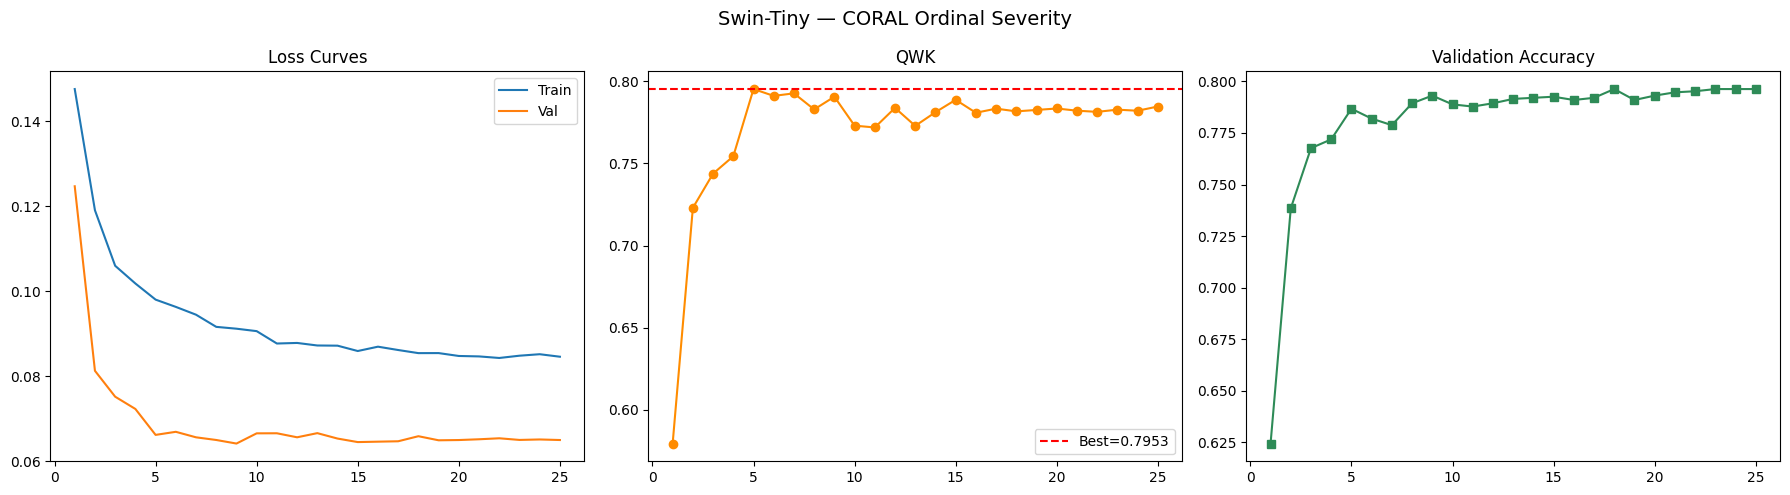

✅ NB4 complete. Weights: /kaggle/working/swin_severity/swin_severity_best.pth


In [9]:
# ─────────────────────────────────────────────────────────────────
# CELL 9 ─ Training Curves
# ─────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
E = range(1, len(history['train_loss']) + 1)
axes[0].plot(E, history['train_loss'], label='Train'); axes[0].plot(E, history['val_loss'], label='Val')
axes[0].set_title('Loss Curves'); axes[0].legend()
axes[1].plot(E, history['val_qwk'], color='darkorange', marker='o')
axes[1].axhline(best_qwk, ls='--', color='red', label=f'Best={best_qwk:.4f}')
axes[1].set_title('QWK'); axes[1].legend()
axes[2].plot(E, history['val_acc'], color='seagreen', marker='s')
axes[2].set_title('Validation Accuracy')
plt.suptitle('Swin-Tiny — CORAL Ordinal Severity', fontsize=14)
plt.tight_layout()
plt.savefig(f"{CFG['output_dir']}/swin_curves.png", dpi=120, bbox_inches='tight')
plt.show()
print('✅ NB4 complete. Weights:', CKPT_PATH)